In [1]:
import torch
import torch.nn as nn
from dataclasses import dataclass
from typing import Callable


DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.11.0+cu128
CUDA available: True
Device: cuda:0
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: 8.0 GB


# Функции для ДУ

In [2]:
derivative = lambda W, x: torch.autograd.grad(
    W,
    x,
    grad_outputs=torch.ones_like(W),
    create_graph=True
)[0]

dW_dx = lambda W, x: derivative(W, x)
d2W_dx2 = lambda W, x: derivative(dW_dx(W, x), x)
d3W_dx3 = lambda W, x: derivative(d2W_dx2(W, x), x)
d4W_dx4 = lambda W, x: derivative(d3W_dx3(W, x), x)

d2W_dxdy = lambda W, x, y: derivative(dW_dx(W, x), y)

d4W_dx2dy2 = lambda W, x, y: derivative(
    derivative(d2W_dx2(W, x), y), y
)

D4 = lambda W, x, y: (
    d4W_dx4(W, x)
    + 2 * d4W_dx2dy2(W, x, y)
    + d4W_dx4(W, y)
)



# Физическая интерпритация


Полная система:
$$
\begin{cases}
A (W(x, y)) |_{\Omega} = F(x, y) \\
B(W(x,y))|_{\partial\Omega} = G(x, y) \\
\end{cases}
$$

### Общие классы для описания граничных условий и внутренних точек произвольной пластины


In [3]:
Tensor = torch.Tensor
PointGenerator = Callable[..., tuple[Tensor, ...]]
LossFunction = Callable[..., Tensor]

# класс для описания граничных условий
@dataclass
class Boundary:
    generator: PointGenerator  # генератор точек на границе
    losses: list[LossFunction] # список функций потерь для каждой граничной точки

# класс для описания внутренних точек
@dataclass
class Interior:
    generator: PointGenerator # генератор внутренних точек
    losses: list[LossFunction] # список функций потерь для каждой внутренней точки

# класс для описания пластины: набор граничных условий и внутренних точек
@dataclass
class Plate:
    interior: Interior
    boundaries: tuple[Boundary, ...]

    def interior_points(self, n: int):
        return self.interior.generator(n)

    def boundary_points(self, n: int):
        return tuple(
            boundary.generator(n)
            for boundary in self.boundaries
        )


In [4]:
def plate_loss_function(
    model: nn.Module,
    plate: Plate,
    boundary_points_n: int = 25,
    interior_points_n: int = 100
):
    # PDE внутри пластины
    x, y = plate.interior_points(interior_points_n)
    x, y = x.reshape(-1), y.reshape(-1)

    W = model(x, y)

    interior_loss = torch.stack([
        loss(W, x, y)
        for loss in plate.interior.losses
    ]).mean()

    # Потери границ
    boundary_losses = []

    for boundary in plate.boundaries:
        xb, yb = boundary.generator(boundary_points_n)
        xb, yb = xb.reshape(-1), yb.reshape(-1)

        Wb = model(xb, yb)

        current_losses = [
            loss(Wb, xb, yb)
            for loss in boundary.losses
        ]

        boundary_losses.extend(current_losses)

    boundary_loss = torch.stack(boundary_losses).mean()

    return interior_loss, boundary_loss

# Весь класс для обученя и визуализации результатов

In [5]:
import os
from typing import Callable, Optional

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import optim
from tqdm import tqdm


class SolutionMethods:
    def __init__(
        self,
        model: torch.nn.Module,
        loss_function: Callable[..., tuple[torch.Tensor, torch.Tensor]],
        analytical_solution_function: Callable[..., torch.Tensor],
        plate=None,
        device=None,
    ):
        self.device = device or torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.model = model.to(self.device)
        self.loss_function = loss_function
        self.analytical_solution_function = analytical_solution_function
        self.plate = plate

        self.analytical_solution = None
        self.model_solution = None
        self.difference = None

        self.history_data = {
            "loss": [],
            "interior_losses": [],
            "boundary_losses": [],
        }

        self.best_loss = float("inf")
        self.best_epoch = None

    # Обучение PINN
    def fit(
        self,
        optimizer: optim.Optimizer,
        scheduler: Optional[optim.lr_scheduler.LRScheduler],
        num_epochs: int,
        boundary_points_n: int = 25,
        interior_points_n: int = 100,
        lambda_bound: float = 4.0,
        lambda_iter: float = 2.0,
        force_coefs: tuple[float, float] = [1.0, 1.0],
        force_times: int = 500,
        last_change: int = 1000,
        checkpoint_path: str = "checkpoints/best_model.pt",
    ):
        if self.plate is None:
            raise ValueError("Передай plate в конструктор SolutionMethods.")

        model = self.model
        os.makedirs(os.path.dirname(checkpoint_path) or ".", exist_ok=True)

        self.history_data = {
            "loss": [],
            "interior_losses": [],
            "boundary_losses": [],
        }

        best_loss = float("inf")
        progress = tqdm(range(num_epochs), desc="Training PINN")

        for epoch in progress:
            # Изменение весов функций потерь
            if (
                force_times > 0
                and epoch > 0
                and epoch % force_times == 0
                and epoch < last_change
            ):
                lambda_bound *= force_coefs[0]
                lambda_iter *= force_coefs[1]

            model.train()
            optimizer.zero_grad(set_to_none=True)

            interior_loss, boundary_loss = self.loss_function(
                model,
                self.plate,
                boundary_points_n,
                interior_points_n,
            )

            loss = lambda_iter * interior_loss + lambda_bound * boundary_loss

            loss.backward()
            optimizer.step()

            # Численные значения
            loss_value = loss.detach().item()
            interior_value = interior_loss.detach().item()
            boundary_value = boundary_loss.detach().item()

            self.history_data["loss"].append(loss_value)
            self.history_data["interior_losses"].append(interior_value)
            self.history_data["boundary_losses"].append(boundary_value)

            saved = False

            # Сохраняем лучшую модель по взвешенному loss
            if np.isfinite(loss_value) and best_loss > (interior_value + boundary_value):
                best_loss = loss_value
                self.best_loss = best_loss
                self.best_epoch = epoch + 1

                torch.save(
                    {
                        "epoch": epoch + 1,
                        "model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "scheduler_state_dict": (
                            scheduler.state_dict() if scheduler is not None else None
                        ),
                        "loss": loss_value,
                        "interior_loss": interior_value,
                        "boundary_loss": boundary_value,
                    },
                    checkpoint_path,
                )
                saved = True

            # Scheduler обновляется каждую эпоху
            if isinstance(
                scheduler,
                optim.lr_scheduler.ReduceLROnPlateau,
            ):
                scheduler.step(loss_value)
            elif scheduler is not None:
                scheduler.step()

            progress.set_postfix(
                loss=f"{loss_value:.3e}",
                best=f"{best_loss:.3e}",
                interior=f"{interior_value:.3e}",
                boundary=f"{boundary_value:.3e}",
                saved="YES" if saved else "",
            )

        print("\nОбучение завершено.")
        print(f"Лучший loss: {best_loss:.6e}")
        print(f"Лучшая эпоха: {self.best_epoch}")
        print(f"Чекпоинт: {checkpoint_path}")

        # Загружаем лучшую модель, а не оставляем веса последней эпохи
        self.load(checkpoint_path)

        return self.history_data

    # Графики истории обучения
    def plot_history(self):
        losses = self.history_data["loss"]
        interior_losses = self.history_data["interior_losses"]
        boundary_losses = self.history_data["boundary_losses"]

        if not losses:
            raise ValueError("История обучения пуста. Сначала вызови fit().")

        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        epochs = np.arange(1, len(losses) + 1)
        tail_start = int(len(losses) * 0.8)

        # Всё обучение
        axes[0].plot(epochs, losses, label="loss")
        axes[0].plot(epochs, interior_losses, label="interior_loss")
        axes[0].plot(epochs, boundary_losses, label="boundary_loss")

        axes[0].set_xlabel("Эпоха")
        axes[0].set_ylabel("Loss")
        axes[0].set_title("Всё обучение")
        axes[0].set_yscale("log")
        axes[0].grid(True, which="both", alpha=0.3)
        axes[0].legend()

        # Последние 20%
        axes[1].plot(
            epochs[tail_start:],
            losses[tail_start:],
            label="loss",
        )
        axes[1].plot(
            epochs[tail_start:],
            interior_losses[tail_start:],
            label="interior_loss",
        )
        axes[1].plot(
            epochs[tail_start:],
            boundary_losses[tail_start:],
            label="boundary_loss",
        )

        axes[1].set_xlabel("Эпоха")
        axes[1].set_ylabel("Loss")
        axes[1].set_title("Последние 20% обучения")
        axes[1].set_yscale("log")
        axes[1].grid(True, which="both", alpha=0.3)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    # Загрузка чекпоинта
    def load(
        self,
        file: str,
        optimizer: Optional[optim.Optimizer] = None,
        scheduler: Optional[optim.lr_scheduler.LRScheduler] = None,
    ):
        checkpoint = torch.load(file, map_location=self.device)

        # Поддерживаем и полный чекпоинт, и обычный state_dict
        if "model_state_dict" in checkpoint:
            self.model.load_state_dict(checkpoint["model_state_dict"])

            if optimizer is not None and "optimizer_state_dict" in checkpoint:
                optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

            scheduler_state = checkpoint.get("scheduler_state_dict")
            if scheduler is not None and scheduler_state is not None:
                scheduler.load_state_dict(scheduler_state)

            self.best_loss = checkpoint.get("loss", float("inf"))
            self.best_epoch = checkpoint.get("epoch")
        else:
            self.model.load_state_dict(checkpoint)

        self.model.to(self.device)
        self.model.eval()

        return self.model

    # Вычисление аналитического решения
    def analytical_solu(self, X_points, Y_points, *args, **kwargs):
        self.analytical_solution = self.analytical_solution_function(
            X_points, Y_points, *args, **kwargs
        )
        return self.analytical_solution

    # Решение PINN с учётом масштабирования
    def unscale_solu(
        self,
        X,
        Y,
        scale_fn: Optional[Callable[..., torch.Tensor]] = None,
    ):
        self.model.eval()

        X = torch.as_tensor(X, dtype=torch.float32, device=self.device)
        Y = torch.as_tensor(Y, dtype=torch.float32, device=self.device)

        with torch.no_grad():
            solution = self.model(X, Y)

            if scale_fn is not None:
                solution = scale_fn(solution)

        self.model_solution = solution
        return self.model_solution

    # Сравнение с аналитическим решением
    def compare_solutions(self):
        if self.analytical_solution is None:
            raise ValueError("Сначала вычисли analytical_solu().")

        if self.model_solution is None:
            raise ValueError("Сначала вычисли unscale_solu().")

        analytical = torch.as_tensor(
            self.analytical_solution,
            dtype=torch.float32,
            device=self.device,
        )
        predicted = torch.as_tensor(
            self.model_solution,
            dtype=torch.float32,
            device=self.device,
        )

        self.difference = predicted - analytical

        rmse = torch.sqrt(torch.mean(self.difference**2)).item()
        mae = torch.mean(torch.abs(self.difference)).item()

        denominator = torch.linalg.vector_norm(analytical).item()
        relative_l2 = (
            torch.linalg.vector_norm(self.difference).item() / denominator
            if denominator > 0
            else float("nan")
        )

        metrics = {
            "RMSE": rmse,
            "MAE": mae,
            "relative_L2": relative_l2,
            "max_error": torch.max(torch.abs(self.difference)).item(),
        }

        print(f"RMSE:      {metrics['RMSE']:.6e}")
        print(f"MAE:       {metrics['MAE']:.6e}")
        print(f"Relative L2: {metrics['relative_L2']:.4%}")
        print(f"Max error: {metrics['max_error']:.6e}")

        return metrics
        
    # evaluation
    def evaluate(
        self,
        a: float,
        b: float,
        D: float,
        q: float,
        N: int = 101,
        D0: float = 1.0,
        q0: float = 1.0,
        normalized_inputs: bool = True,
        scale_output: bool = False,
    ):
        if N < 2:
            raise ValueError("N должно быть не меньше 2.")
        if a <= 0 or b <= 0 or D <= 0:
            raise ValueError("a, b и D должны быть положительными.")
        if scale_output and (D0 <= 0 or q0 == 0):
            raise ValueError("Для масштабирования нужны D0 > 0 и q0 != 0.")

        # Физическая сетка
        x = np.linspace(0, a, N)
        y = np.linspace(0, b, N)
        X, Y = np.meshgrid(x, y)

        # Координаты модели
        if normalized_inputs:
            X_model = X / a
            Y_model = Y / b
        else:
            X_model = X
            Y_model = Y

        self.model.eval()
        parameter = next(self.model.parameters())

        x_t = torch.as_tensor(
            X_model.ravel(),
            dtype=parameter.dtype,
            device=parameter.device,
        )
        y_t = torch.as_tensor(
            Y_model.ravel(),
            dtype=parameter.dtype,
            device=parameter.device,
        )

        # Предсказание PINN
        with torch.no_grad():
            W_pinn = (
                self.model(x_t, y_t)
                .detach()
                .cpu()
                .numpy()
                .reshape(N, N)
            )

        # Масштабирование выхода, если сеть обучалась
        # на физическом прогибе при базовых D0 и q0.
        if scale_output:
            W_pinn *= (q / D) / (q0 / D0)

        # Аналитическое решение
        W_ref = self.analytical_solution_function(X, Y, a=a, b=b, D=D, q=q)
        W_ref = np.asarray(W_ref).reshape(N, N)

        # Метрики
        error = W_pinn - W_ref
        rmse = np.sqrt(np.mean(error**2))

        ref_norm = np.linalg.norm(W_ref.ravel())
        relative_l2 = (
            np.linalg.norm(error.ravel()) / ref_norm * 100
            if ref_norm > 0 else float("nan")
        )

        ref_max = np.max(np.abs(W_ref))
        max_error_percent = (
            np.max(np.abs(error)) / ref_max * 100
            if ref_max > 0 else float("nan")
        )

        self.X = X
        self.Y = Y
        self.analytical_solution = W_ref
        self.model_solution = W_pinn
        self.difference = error

        self.metrics = {
            "RMSE": rmse,
            "relative_L2_percent": relative_l2,
            "max_error_percent": max_error_percent,
        }

        print(f"D: {D:.6e} Н·м")
        print(f"Максимум |W_ref|:  {np.max(np.abs(W_ref)):.6e} м")
        print(f"Максимум |W_PINN|: {np.max(np.abs(W_pinn)):.6e} м")
        print(f"RMSE:              {rmse:.6e} м")
        print(f"Относительная L2:  {relative_l2:.4f}%")
        print(f"Максимальная ошибка: {max_error_percent:.4f}%")

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        for ax, (Z, title) in zip(
            axes,
            [
                (W_ref, "Аналитическое решение"),
                (W_pinn, "PINN"),
                (np.abs(error), "Абсолютная ошибка"),
            ],
        ):
            contour = ax.contourf(X, Y, Z, levels=50, cmap="viridis")
            ax.set_xlabel("x, м")
            ax.set_ylabel("y, м")
            ax.set_title(title)
            ax.set_aspect("equal")
            fig.colorbar(contour, ax=ax)

        plt.tight_layout()
        plt.show()

        return self.metrics

### BASE PIPELINE

In [6]:

import torch.nn as nn
from torch import optim
from pathlib import Path

# === PIPELINE ОБУЧЕНИЯ ===
def pipeline(
        model: torch.nn.Module,
        optimizer: torch.optim.Optimizer,
        scheduler: torch.optim.lr_scheduler._LRScheduler,
        plate: Plate,
        checkpoint_path: str,
        num_epochs: int,
        boundary_points_n: int,
        interior_points_n: int,
        lambda_bound: float,
        lambda_iter: float,
        force_coefs: tuple,
        force_times: int,
        last_change: int,
        loss_function,
        analytical_solution_function,
        a: float = 1,
        b: float = 1,
        D: float = 1,
        q: float = 1, 
):

        # Убедимся, что функции генерации и модель используют одно устройство.
        DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        print("Device:", DEVICE)


        # Создание модели и тренера.

        #model = model().to(DEVICE)


        solver = SolutionMethods(
        model=model,
        loss_function=loss_function,
        analytical_solution_function=analytical_solution_function,
        plate=plate,
        device=DEVICE,
        )

        LOAD_CHECKPOINT = None

        if LOAD_CHECKPOINT is not None:
                solver.load(LOAD_CHECKPOINT, optimizer=optimizer, scheduler=scheduler)

        # 6. Запуск обучения.
        history = solver.fit(
                optimizer,
                scheduler,
                num_epochs=num_epochs,
                boundary_points_n=boundary_points_n,
                interior_points_n=interior_points_n,
                lambda_bound=lambda_bound, 
                lambda_iter=lambda_iter,
                force_coefs=force_coefs,
                force_times=force_times,
                last_change=last_change,
        )

        solver.plot_history()

        print("Best epoch:", solver.best_epoch)
        print("Best loss:", solver.best_loss)
        print("Checkpoint:", checkpoint_path)

        solver.evaluate(a=a, b=b, D=D, q=q, N=101, D0=1.0, q0=1.0, normalized_inputs=True, scale_output=True)


# Квадратная пластина с равномерной распределенной нагрузкой

In [181]:
a, b, q, D = 1.0, 1.0, 1.0, 1.0

## Описание

Полная система:
$$
\begin{cases}
D\Delta^2 W(x,y)|_{\Omega} = q \\
W(x,y)|_{\partial\Omega} = 0 \\
\frac{\partial^2 W}{\partial^2 x}|_{\partial\Omega_1  \cup\Omega_3} = 0 \\
\frac{\partial^2 W}{\partial^2 y}|_{\partial\Omega_2  \cup\Omega_4} = 0
\end{cases}
$$

### Конкретная реализация генератора точек на границе прямоугольной пластины

`loss fun-s`

In [7]:
zero_loss = lambda W, x, y: W.square().mean()


def random_x(n):
    return (a * torch.rand(n, device=DEVICE)).requires_grad_()


def random_y(n):
    return (b * torch.rand(n, device=DEVICE)).requires_grad_()


def zero_x(n):
    return torch.zeros(n, device=DEVICE).requires_grad_()


def zero_y(n):
    return torch.zeros(n, device=DEVICE).requires_grad_()


def const_x(n):
    return torch.full((n,), a, device=DEVICE).requires_grad_()


def const_y(n):
    return torch.full((n,), b, device=DEVICE).requires_grad_()


left_boundary = Boundary(
    generator=lambda n: (zero_x(n), random_y(n)),
    losses=[
        zero_loss,
        lambda W, x, y: d2W_dx2(W, x).square().mean()
    ]
)

right_boundary = Boundary(
    generator=lambda n: (const_x(n), random_y(n)),
    losses=[
        zero_loss,
        lambda W, x, y: d2W_dx2(W, x).square().mean()
    ]
)

upper_boundary = Boundary(
    generator=lambda n: (random_x(n), const_y(n)),
    losses=[
        zero_loss,
        lambda W, x, y: d2W_dx2(W, y).square().mean()
    ]
)

down_boundary = Boundary(
    generator=lambda n: (random_x(n), zero_y(n)),
    losses=[
        zero_loss,
        lambda W, x, y: d2W_dx2(W, y).square().mean()
    ]
)

interior = Interior(
    generator=lambda n: (random_x(n), random_y(n)),
    losses=[
        lambda W, x, y, D=1: (
            D * D4(W, x, y) - torch.tensor(q, device=DEVICE).requires_grad_()
            #Function(x, y)
        ).square().mean()
    ]
)

boundaries = (
    left_boundary,
    right_boundary,
    upper_boundary,
    down_boundary
)

plate = Plate(interior=interior, boundaries=boundaries)

`Model`

In [8]:
import torch
import torch.nn as nn


class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
        )

        self.activation = nn.Tanh()

    def forward(self, x):
        return self.activation(x + self.block(x))


class PlatePINN(nn.Module):
    def __init__(
        self,
        input_dim=2,
        hidden_dim=32,
        output_dim=1,
        num_blocks=6,
        a=1.0,
        b=1.0,
    ):
        super().__init__()

        self.a = a
        self.b = b

        self.input_layer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
        )

        self.res_blocks = nn.Sequential(
            *[
                ResidualBlock(hidden_dim)
                for _ in range(num_blocks)
            ]
        )

        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, y):
        x_flat = x.reshape(-1)
        y_flat = y.reshape(-1)

        xy = torch.stack((x_flat, y_flat), dim=1)

        z = self.input_layer(xy)
        z = self.res_blocks(z)

        raw = self.output_layer(z).squeeze(-1)

        # Жёсткое выполнение W = 0 на границах
        boundary_factor = (
            x_flat
            * (self.a - x_flat)
            * y_flat
            * (self.b - y_flat)
        )

        return boundary_factor * raw

`navier solution`

In [9]:
# АНАЛИТИЧЕСКОЕ РЕШЕНИЕ НАВЬЕ
def navier_solution(
    X: torch.Tensor,
    Y: torch.Tensor,
    a: float = 1,
    b: float = 1,
    D: float = 1,
    q: float = 1,
    n_terms: int = 441,
):
    """
    X, Y — двумерные массивы координат.
    n_terms — число нечётных гармоник по каждому направлению.
    """
    W = np.zeros_like(X, dtype=np.float64)

    odd_numbers = range(1, n_terms + 1, 2)

    for m in odd_numbers:
        for n in odd_numbers:
            coefficient = (
                16 * q / (np.pi**6 * D * m * n * (m**2 / a**2 + n**2 / b**2) ** 2)
            )

            W += coefficient * np.sin(m * np.pi * X / a) * np.sin(n * np.pi * Y / b)

    return W

## pipeline

Device: cuda:0


Training PINN: 100%|██████████| 1200/1200 [26:43<00:00,  1.34s/it, best=1.589e-02, boundary=1.149e-06, interior=9.950e-04, loss=1.589e-02, saved=YES]



Обучение завершено.
Лучший loss: 1.589351e-02
Лучшая эпоха: 1200
Чекпоинт: checkpoints/best_model.pt


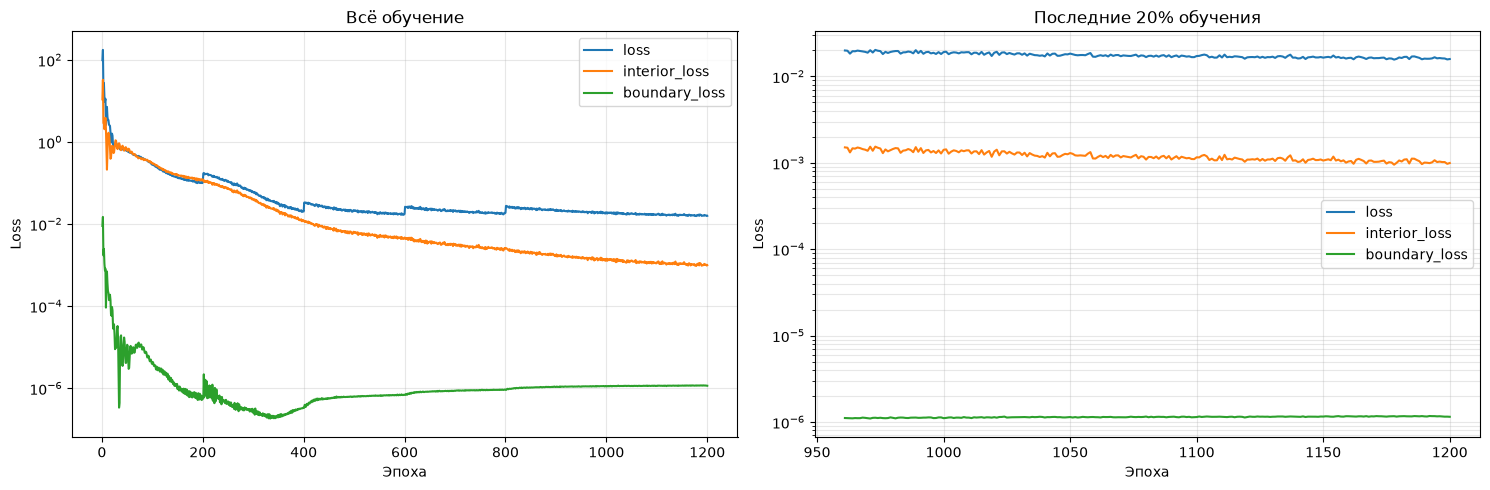

Best epoch: 1200
Best loss: 0.01589350774884224
Checkpoint: checkpoints/plate_pinn_best.pt


In [ ]:
# === PIPELINE ОБУЧЕНИЯ ===
# D4, Boundary, Interior, Plate, loss_function, SolutionMethods, plate, a, b, q, D.

import torch.nn as nn
from torch import optim
from pathlib import Path


# Убедимся, что функции генерации и модель используют одно устройство.
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


# Создание модели и тренера.

model = PlatePINN(
    input_dim=2,
    hidden_dim=32,
    output_dim=1,
    num_blocks=6
).to(DEVICE)

optimizer = optim.AdamW(model.parameters(), lr=0.01, betas=(0.9, 0.999))
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=80, gamma=0.8) 

solver = SolutionMethods(
    model=model,
    loss_function=plate_loss_function,
    analytical_solution_function=navier_solution,
    plate=plate,
    device=DEVICE,
)


LOAD_CHECKPOINT = None

if LOAD_CHECKPOINT is not None:
    solver.load(LOAD_CHECKPOINT, optimizer=optimizer, scheduler=scheduler)

# 6. Запуск обучения.
checkpoint_path = "checkpoints/plate_pinn_best.pt"
history = solver.fit(
    optimizer,
    scheduler,
    num_epochs=1200,
    boundary_points_n=10000,
    interior_points_n=10000,
    lambda_bound=1e4, 
    lambda_iter=0.8,
    force_coefs=(0.9, 1.8),
    force_times=200,
    last_change=1000,
)

solver.plot_history()

print("Best epoch:", solver.best_epoch)
print("Best loss:", solver.best_loss)
print("Checkpoint:", checkpoint_path)


In [103]:
print(solver.analytical_solution_function)

<function navier_solution at 0x0000017881313E20>


D: 1.000000e+01 Н·м
Максимум |W_ref|:  3.249882e+03 м
Максимум |W_PINN|: 3.255564e+03 м
RMSE:              5.055055e+00 м
Относительная L2:  0.3067%
Максимальная ошибка: 0.4741%


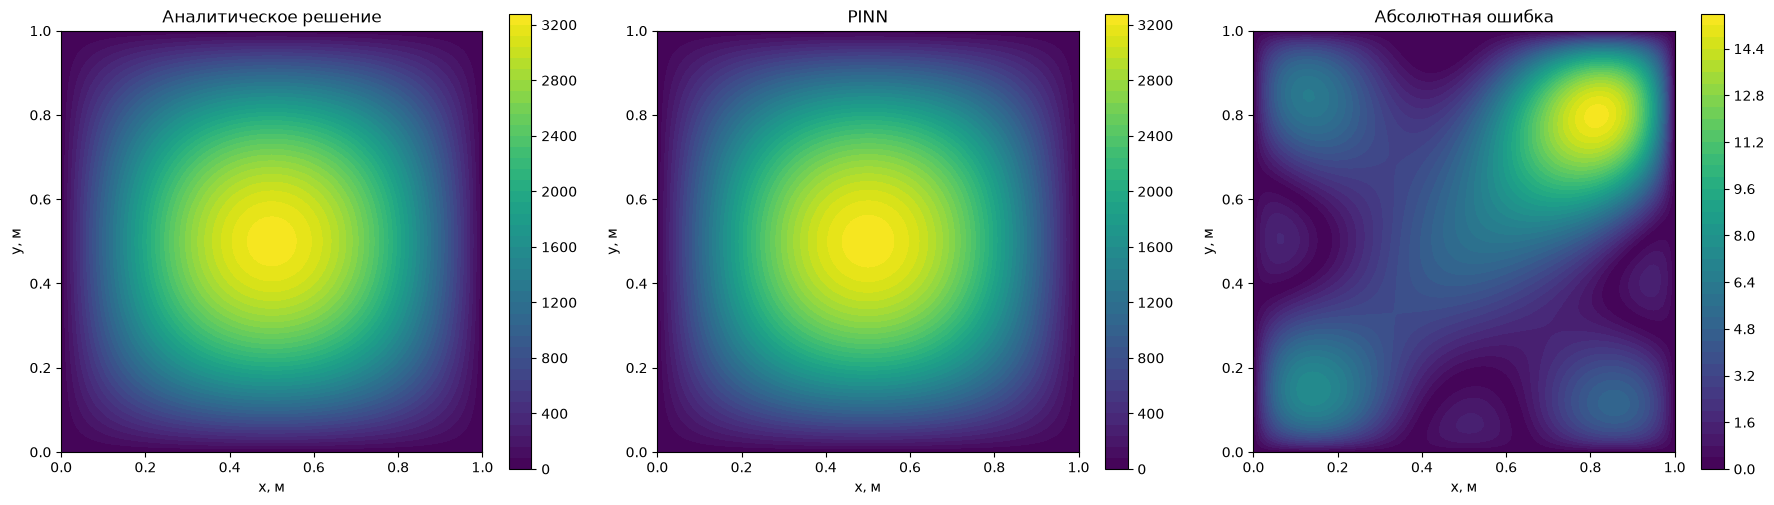

{'RMSE': np.float64(5.055054802529991),
 'relative_L2_percent': np.float64(0.306724335403284),
 'max_error_percent': np.float64(0.47406388775324915)}

In [114]:
solver.evaluate(a=1, b=1, D=10, q=8000000, N=101, D0=1.0, q0=1.0, normalized_inputs=True, scale_output=True)

# Пластинки из статьи 
`PHYSICS-INFORMED NEURAL NETWORKS FOR ELASTIC PLATE PROBLEMS WITH BENDING AND WINKLER-TYPE CONTACT EFFECTS`

## Модель 1

### Физическая постановка

Система:
$$
\begin{cases}
D\Delta^2 W(x,y)|_{\Omega} = F(x, y) \\
W(x,y)|_{\partial\Omega} = 0 \\
\frac{\partial^2 W}{\partial^2 x}|_{\partial\Omega_1  \cup\Omega_3} = 0 \\
\frac{\partial^2 W}{\partial^2 y}|_{\partial\Omega_2  \cup\Omega_4} = 0
\end{cases}
$$
где $F(x, y)$ выражается уравнением:
$$
F(x, y) = A \sin(\pi x)\sin(\pi y)
$$.
Для данного уравнения существует эталонное аналитическое решение:
$$
W(x, y) = \frac{\sin(\pi x)\sin(\pi y)}{4 \pi ^ 4 D}.
$$
На обучении примем $A = 1$, $D=1$.

In [185]:
sin_f = lambda x, y: torch.sin(np.pi * x) * torch.sin(np.pi * y)

In [186]:
# В функции потерь меняется только член, ответственный за внутренние точки

'''
left_boundary, right_boundary, upper_boundary, down_boundary
из предыдущего примера
'''
# 
interior = Interior(
    generator=lambda n: (random_x(n), random_y(n)),
    losses=[
        lambda W, x, y: (
            D4(W, x, y) - sin_f(x, y).requires_grad_()
        ).square().mean()
    ]
)

boundaries = (
    left_boundary,
    right_boundary,
    upper_boundary,
    down_boundary
)

sin_plate = Plate(interior=interior, boundaries=boundaries)

In [187]:
# АНАЛИТИЧЕСКОЕ РЕШЕНИЕ
def simple_sinus_solution(X, Y, a=1.0, b=1.0, D=1.0, q=1.0):
    """
    X, Y — двумерные массивы координат.
    n_terms — число нечётных гармоник по каждому направлению.
    """
    return (
        q * np.sin(np.pi * X / a) * np.sin(np.pi * Y / b)
        / (D * np.pi**4 * (1 / a**2 + 1 / b**2)**2)
    )

### pipeline

Device: cuda:0


Training PINN: 100%|██████████| 350/350 [03:08<00:00,  1.86it/s, best=9.705e-04, boundary=3.975e-07, interior=7.143e-04, loss=9.705e-04, saved=YES]



Обучение завершено.
Лучший loss: 9.704733e-04
Лучшая эпоха: 350
Чекпоинт: checkpoints/best_model.pt


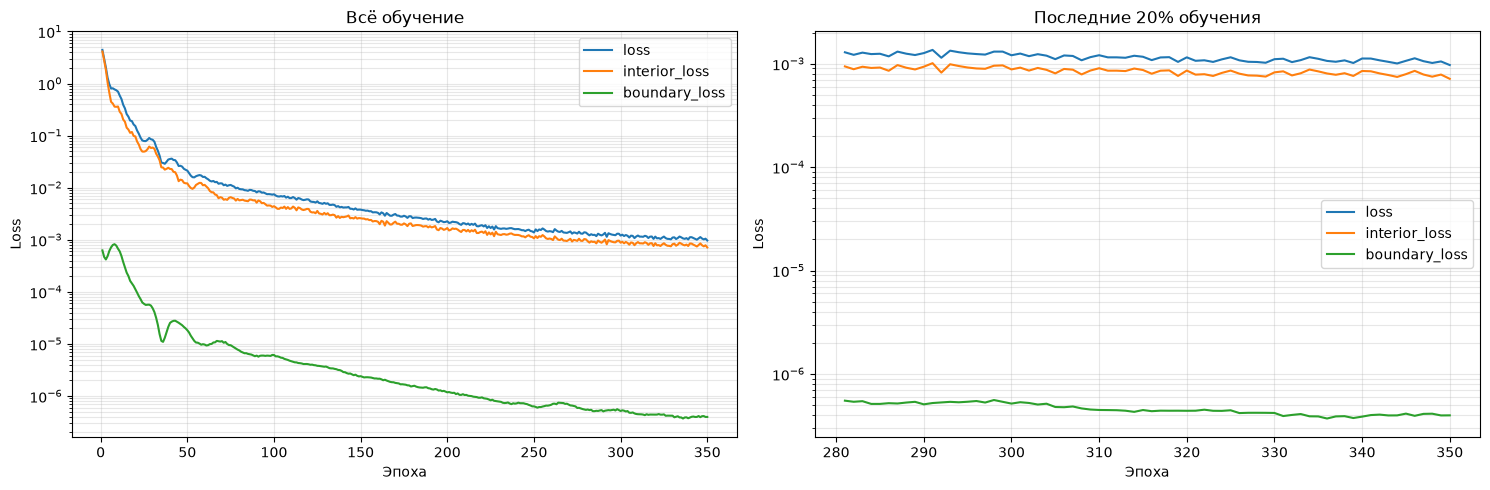

Best epoch: 350
Best loss: 0.0009704732801765203
Checkpoint: checkpoints/sin_plate_pinn_best.pt
D: 1.000000e+00 Н·м
Максимум |W_ref|:  2.566496e-03 м
Максимум |W_PINN|: 2.560366e-03 м
RMSE:              8.540709e-06 м
Относительная L2:  0.6722%
Максимальная ошибка: 0.7479%


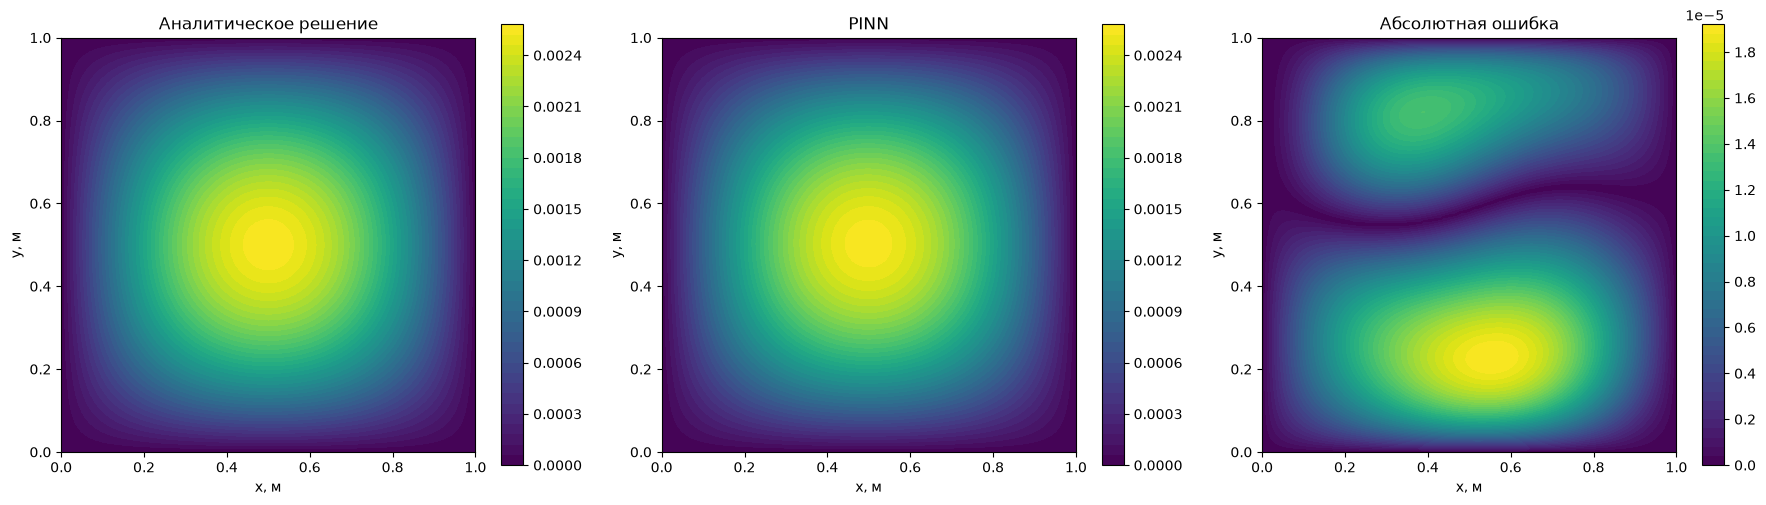

In [189]:
sin_model = PlatePINN(
    input_dim=2,
    hidden_dim=16,
    output_dim=1,
    num_blocks=4).to(DEVICE)
sin_optimizer = optim.AdamW(sin_model.parameters(), lr=0.001, betas=(0.9, 0.999))
sin_scheduler = optim.lr_scheduler.StepLR(sin_optimizer, step_size=80, gamma=0.8)
pipeline(
        model= sin_model,
        optimizer =sin_optimizer,
        scheduler = sin_scheduler,
        checkpoint_path = "checkpoints/sin_plate_pinn_best.pt",
        plate = sin_plate,
        num_epochs = 350,
        boundary_points_n = 1000,
        interior_points_n = 1000,
        lambda_bound = 5e2,
        lambda_iter = 1.,
        force_coefs = (0.75, 1.15),
        force_times = 250,
        last_change = 1000,
        loss_function=plate_loss_function,
        analytical_solution_function=simple_sinus_solution,
)

## Модель 2

Система:
$$
\begin{cases}
D\Delta^2 W(x,y) + k_1 W − k_2 𝑊^3|_{\Omega}= F(x, y) \\
W(x,y)|_{\partial\Omega} = 0 \\
\frac{\partial^2 W}{\partial^2 x}|_{\partial\Omega_1  \cup\Omega_3} = 0 \\
\frac{\partial^2 W}{\partial^2 y}|_{\partial\Omega_2  \cup\Omega_4} = 0
\end{cases}
$$
где $F(x, y)$ выражается уравнением:
$$
F(x, y) = A \sin(\pi x)\sin(\pi y)
$$.
Для данного уравнения существует эталонное аналитическое решение отсутствует.

Ситуация интереснее: очевидно, решение должно работать при любых $k_1$, $k_2$, $A$, $D$.
Соответственно, введу параметры:

$\hat{k_1}=\frac{k_1}{D}$, $\hat{k_2}=\frac{k_2}{D}$, $\hat{A}=\frac{A}{D}$.
$$
\Delta^2 W(x,y) + \hat{k_1} W− \hat{k_2} 𝑊^3|_{\Omega} = \hat{A} \sin(\pi x)\sin(\pi y);
$$
Если представить $W(x,y)=\hat{A}u(x, y)$ 
$$
\Delta^2 u + \hat{k_1} u − \hat{k_2}\hat{A}^2 u^3|_{\Omega} = \sin(\pi x)\sin(\pi y);
$$ =>
$$
\Delta^2 u + \hat{k_1} u − \gamma u^3|_{\Omega} = \sin(\pi x)\sin(\pi y);
$$
Итого, требуется обучить $u(x, y, \hat{k_1}, \gamma| \Theta)$.

In [ ]:
# В функции потерь меняется только член, ответственный за внутренние точки
'''
left_boundary, right_boundary, upper_boundary, down_boundary
из предыдущего примера
'''
interior = Interior(
    generator=lambda n: (random_x(n), random_y(n)),
    losses=[
        lambda W, x, y, k, gamma: (
            D4(W, x, y) + k * W(x, y) - gamma * (W(x, y)) ** 3 - sin_f(x, y).requires_grad_()
        ).square().mean()
    ]
)

boundaries = (
    left_boundary,
    right_boundary,
    upper_boundary,
    down_boundary
)

sin_plate_with_k1k2 = Plate(interior=interior, boundaries=boundaries)